# Logistics Data Analytics Internship

## Week 1: Data Collection and Cleaning | Week 2: Exploratory Data Analysis

**Dataset:** DataCo Smart Supply Chain Dataset  
**Tools:** Python, Pandas, NumPy, Matplotlib and Seaborn

### Project objective
This project prepares logistics data for analysis and explores order-shipping performance. Week 1 focuses on data inspection, cleaning, feature creation and validation. Week 2 builds on the cleaned dataset through descriptive statistics, correlation analysis and visualizations.

### Notebook workflow
1. Load and inspect the dataset.
2. Identify and handle missing values and unnecessary columns.
3. convert date fields and create shipping-related features.
4. Validate the calculated shipping duration and classify delivery performance.
5. Explore numerical variables and visualize important relationships.

**Note:** This notebook retains the original Week 1 work and adds the Week 2 EDA work. Run the cells from top to bottom in Google Colab. The dataset path may need to be adjusted to match your Google Drive location.


## 1. Import libraries
The following libraries support data handling, numerical operations and visualization.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas and basic libraries imported successfully!")


Pandas and basic libraries imported successfully!


## 2. Connect to Google Drive
The dataset is stored in Google Drive, so Drive is mounted before locating the CSV file.

In [2]:
# Importing OS to get list of directory content
import os

print(os.listdir('/content'))


['.config', 'shipping_status.png', 'shipping_duration_histogram.png', 'Histogram_shipping_Duration.png', 'shipping_duration_boxplot.png', 'Sales_Vs_Shipping_Duration.png', 'correlation_heatmap.png', 'sales_vs_shipping_duration.png', 'shipping_duration_scatter.png', 'BoxPlot_shipping_Duration.png', 'drive', 'sample_data']


In [3]:
# Mount Google colab to Drive content
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Get Path of the dataset Directory
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == 'DataCoSupplyChainDataset.csv':
            print(os.path.join(root, file))

/content/drive/MyDrive/DataCoSupplyChainDataset.csv


## 3. Load the dataset
The CSV file is read using `latin-1` encoding, as used in the original notebook. The first shape check confirms the number of records and fields loaded.

In [5]:
# Load Dataset from Google Drive
import pandas as pd

file_path = '/content/drive/MyDrive/DataCoSupplyChainDataset.csv'

df = pd.read_csv(file_path, encoding='latin-1')

display(df.shape)

(180519, 53)

## 4. Initial data exploration
This section checks the dataset dimensions, sample records, column names, data types, missing values, duplicate rows and descriptive statistics.

**Why this matters:** Initial exploration helps identify data-quality issues before cleaning or analysis.

In [6]:
# Initial Data Exploration

#1. Check dataset dimensions
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

#2. View first five records
print("\nFirst 5 records:")
display(df.head())

#3. View last five records
print("\nLast 5 records:")
display(df.tail())

#4. Check column names
print("\nColumn Names:")
display(df.columns)

#5. Check data types non-null values
print("\nData Types and Non-Null Values:")
display(df.info())

#6. Check missing values
print("\nMissing Values:")
display(df.isnull().sum())

#7. Check duplicate records
duplicate_count = df.duplicated().sum()
print("\nTotal duplicate rows:", duplicate_count)
print("Total records:", len(df))
display(duplicate_count)

#8. Generate statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (180519, 53)
Number of Rows: 180519
Number of Columns: 53

First 5 records:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class



Last 5 records:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/18/2016 20:18,Standard Class
180518,PAYMENT,4,4,168.949997,383.980011,Shipping on time,0,45,Fishing,Caguas,...,NaN,1004,45,NaN,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 18:54,Standard Class



Column Names:


Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

... (4 outputs left out)


Total duplicate rows: 0
Total records: 180519


np.int64(0)


Statistical Summary:


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


## 5. Missing-value analysis
Missing values are counted and expressed as a percentage of all records. This helps distinguish columns with a small number of missing entries from columns that are largely incomplete.

In [7]:
# Missing Value Analysis

#1. Calculate missing values
missing_values = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

#2. Combine into a DataFrame for better display
missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percent
})

#3. Filter out columns with 0 missing values
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

if missing_df.empty:
    print("No missing values found in the dataset!")
else:
    print("Columns with missing values:")

display(missing_df)

Columns with missing values:


,Missing Values,Percentage (%)
Product Description,180519,100.000000
Order Zipcode,155679,86.239676
Customer Lname,8,0.004432
Customer Zipcode,3,0.001662


## 6. Create a working copy
A separate copy is used for cleaning so that the original `df` remains unchanged.

In [8]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")
print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Working copy created successfully!
Original shape: (180519, 53)
Working copy shape: (180519, 53)


## 7. Remove highly incomplete columns
The original analysis identifies `Product Description` and `Order Zipcode` as highly incomplete. They are removed from the working dataset to avoid retaining fields with very limited usable information.

**Recorded reason:** `Product Description` is entirely missing and `Order Zipcode` has a high proportion of missing values.

In [9]:
# Working on Unnecessary Columns

#1. Display the 'Order Zipcode' and 'Product Description' columns properly on separate lines
print(" BEFORE DROPPING")
display(df_clean[['Order Zipcode', 'Product Description']])
print("Shape:", df_clean.shape)

#2. Droping Unnecessary Columns
df_clean.drop(
    columns=['Product Description', 'Order Zipcode'],
    inplace=True
)

print("Unnecessary columns removed!")
display("New shape:", df_clean.shape)

#3. After droping
print("AFTER DROPPING")
display(df_clean.head())
print("Shape:", df_clean.shape)




 BEFORE DROPPING


,Order Zipcode,Product Description
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
...,...,...
180514,NaN,NaN
180515,NaN,NaN
180516,NaN,NaN
180517,NaN,NaN


Shape: (180519, 53)
Unnecessary columns removed!


'New shape:'

(180519, 51)

AFTER DROPPING


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


Shape: (180519, 51)


## 8. Handle remaining missing values
The remaining missing entries in customer name and ZIP code fields are replaced with an explicit `Unknown` label. This preserves the records while making missing information visible.

In [10]:
# Analysing Missing Values

#1. Check remaining missing values

missing_values = df_clean.isnull().sum()
display(missing_values[missing_values > 0])

#2. Handle missing values

df_clean['Customer Lname'] = (
    df_clean['Customer Lname'].fillna('Unknown')
)

df_clean['Customer Zipcode'] = (
    df_clean['Customer Zipcode'].fillna('Unknown').astype(str)
)

print("\nMissing values handled successfully!")

#3. Verifying remaining missing values

print("\n Remaining missing values:")
print(df_clean.isnull().sum().sum())

,0
Customer Lname,8
Customer Zipcode,3



Missing values handled successfully!

 Remaining missing values:
0


## 9. Convert date columns
The order and shipping date fields are converted to Pandas datetime values so that date differences can be calculated.

**Validation note:** Because `errors='coerce'` converts unparseable values to `NaT`, inspect the missing-date counts after conversion.

In [11]:
# Find columns containing date or time in their names

date_columns = [
    col for col in df_clean.columns
    if 'date' in col.lower() or 'time' in col.lower()
]

print("Date-related columns:")
print(date_columns)
display(df[['order date (DateOrders)', 'shipping date (DateOrders)']])


# Convert date columns into datetime format

date_columns = [
    'order date (DateOrders)',
    'shipping date (DateOrders)'
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors='coerce')

print("\nDate columns converted successfully!")

# Check the data types
display(df_clean[date_columns].dtypes)

Date-related columns:
['order date (DateOrders)', 'shipping date (DateOrders)']


,order date (DateOrders),shipping date (DateOrders)
0,1/31/2018 22:56,2/3/2018 22:56
1,1/13/2018 12:27,1/18/2018 12:27
2,1/13/2018 12:06,1/17/2018 12:06
3,1/13/2018 11:45,1/16/2018 11:45
4,1/13/2018 11:24,1/15/2018 11:24
...,...,...
180514,1/16/2016 3:40,1/20/2016 3:40
180515,1/16/2016 1:34,1/19/2016 1:34
180516,1/15/2016 21:00,1/20/2016 21:00
180517,1/15/2016 20:18,1/18/2016 20:18



Date columns converted successfully!


,0
order date (DateOrders),datetime64[ns]
shipping date (DateOrders),datetime64[ns]


## 10. Standardize customer ZIP code format
ZIP codes are identifiers rather than quantities, so they should be treated as text. The code below converts the field to a string representation.

In [12]:
# Convert ZIP codes into string format
# . A ZIP code is an identifier, not a numerical quantity
df_clean['Customer Zipcode'] = (
    pd.to_numeric(df_clean['Customer Zipcode'], errors='coerce')
    .astype('Int64')
    .astype('string')
    .fillna('Unknown')
)

print("ZIP codes converted successfully!")

print("Data type:", df_clean['Customer Zipcode'].dtype)
print("Missing values:", df_clean['Customer Zipcode'].isnull().sum())

display(df_clean[['Customer Zipcode']].head())

ZIP codes converted successfully!
Data type: string
Missing values: 0


,Customer Zipcode
0,725
1,725
2,95125
3,90027
4,725


## 11. Create the Shipping Duration feature
Shipping Duration is calculated as the elapsed time between the order date and shipping date, expressed in days. This derived variable is used in the later shipping analysis.

In [13]:
# Calculate shipping duration in days

df_clean['Shipping Duration'] = (
    df_clean['shipping date (DateOrders)'] -
    df_clean['order date (DateOrders)']
).dt.total_seconds() / (24 * 60 * 60)

display(df_clean[
    ['order date (DateOrders)',
     'shipping date (DateOrders)',
     'Shipping Duration']
].head(10))


,order date (DateOrders),shipping date (DateOrders),Shipping Duration
0,2018-01-31 22:56:00,2018-02-03 22:56:00,3.0
1,2018-01-13 12:27:00,2018-01-18 12:27:00,5.0
2,2018-01-13 12:06:00,2018-01-17 12:06:00,4.0
3,2018-01-13 11:45:00,2018-01-16 11:45:00,3.0
4,2018-01-13 11:24:00,2018-01-15 11:24:00,2.0
5,2018-01-13 11:03:00,2018-01-19 11:03:00,6.0
6,2018-01-13 10:42:00,2018-01-15 10:42:00,2.0
7,2018-01-13 10:21:00,2018-01-15 10:21:00,2.0
8,2018-01-13 10:00:00,2018-01-16 10:00:00,3.0
9,2018-01-13 09:39:00,2018-01-15 09:39:00,2.0


## 12. Check Shipping Duration
Summary statistics, negative values and missing values are checked to assess whether the calculated duration is plausible and usable.

In [14]:

# Check shipping duration statistics

print(df_clean['Shipping Duration'].describe())

# Count negative shipping durations
negative_duration = (
    df_clean['Shipping Duration'] < 0
).sum()

print("\nNegative shipping durations:", negative_duration)

# Count missing durations
print("Missing durations:",
      df_clean['Shipping Duration'].isnull().sum())


count    180519.000000
mean          3.498826
std           1.617394
min           0.500000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
Name: Shipping Duration, dtype: float64

Negative shipping durations: 0
Missing durations: 0


## 13. Validate the calculated duration
The calculated Shipping Duration is compared with the dataset's `Days for shipping (real)` field.

- An **exact match** means both values are identical.
- A **rounded match** means the calculated duration matches after rounding to the nearest whole day.

Small differences may arise because the date-time subtraction can retain fractions of a day.

In [15]:
# Analyzing Matching and non matching records with difference calculation

#1. Calculate the difference between 'Days for shipping (real)' and our calculated 'Shipping Duration'
df_clean['Duration Validation Difference'] = df_clean['Days for shipping (real)'] - df_clean['Shipping Duration']

#2. Count exact matches
exact_matches = (df_clean['Days for shipping (real)'] == df_clean['Shipping Duration']).sum()

#3. Count matches when rounded to nearest integer
rounded_matches = (df_clean['Days for shipping (real)'] == df_clean['Shipping Duration'].round()).sum()

print(f"Total orders analyzed: {len(df_clean)}")
print(f"Exact matches: {exact_matches} ({exact_matches / len(df_clean) * 100:.2f}%)")
print(f"Matches when rounded to the nearest integer: {rounded_matches} ({rounded_matches / len(df_clean) * 100:.2f}%)")

#4. Describe the differences
print("\nSummary statistics of the differences (Real - Calculated):")
print(df_clean['Duration Validation Difference'].describe())

#5. Display a sample where they don't match exactly
if exact_matches < len(df_clean):
    print("\nSample records with discrepancies:")
    display(
        df_clean[
            df_clean['Days for shipping (real)'] !=
            df_clean['Shipping Duration']
        ][
            ['order date (DateOrders)',
             'shipping date (DateOrders)',
             'Days for shipping (real)',
             'Shipping Duration',
             'Duration Validation Difference']
    ].head(5))

#6. Non Matching records
non_matching = len(df_clean) - exact_matches

display(f"Non-matching records: {non_matching}")
display(f"Non-matching percentage: {non_matching / len(df_clean) * 100:.2f}%")


Total orders analyzed: 180519
Exact matches: 170782 (94.61%)
Matches when rounded to the nearest integer: 175862 (97.42%)

Summary statistics of the differences (Real - Calculated):
count    180519.000000
mean         -0.001172
std           0.116118
min          -0.500000
25%           0.000000
50%           0.000000
75%           0.000000
max           0.500000
Name: Duration Validation Difference, dtype: float64

Sample records with discrepancies:


,order date (DateOrders),shipping date (DateOrders),Days for shipping (real),Shipping Duration,Duration Validation Difference
19,2018-01-13 06:09:00,2018-01-13 18:09:00,0,0.5,-0.5
20,2018-01-13 05:48:00,2018-01-13 17:48:00,0,0.5,-0.5
38,2018-01-12 23:30:00,2018-01-13 11:30:00,1,0.5,0.5
39,2018-01-12 23:09:00,2018-01-13 11:09:00,1,0.5,0.5
40,2018-01-12 22:48:00,2018-01-13 10:48:00,1,0.5,0.5


'Non-matching records: 9737'

'Non-matching percentage: 5.39%'

## 14. Compare actual and scheduled shipping time
`Scheduled Difference` is calculated as actual shipping days minus scheduled shipping days.

- Negative: delivered earlier than scheduled.
- Zero: delivered on schedule.
- Positive: took longer than scheduled.

This difference is then used to classify each order as Early, On Time or Late.

In [16]:
# Checking Delivery performance

#1. Calculate difference between actual and scheduled shipping

df_clean['Scheduled Difference'] = (
    df_clean['Days for shipping (real)'] -
    df_clean['Days for shipment (scheduled)']
)

#2. Classify shipping performance

df_clean['Shipping Status'] = np.select(
    [
        df_clean['Scheduled Difference'] < 0,
        df_clean['Scheduled Difference'] == 0,
        df_clean['Scheduled Difference'] > 0
    ],
    [
        'Early',
        'On Time',
        'Late'
    ],
    default='Unknown'
)

#3. Display sample results

display(
    df_clean[
        ['Days for shipping (real)',
         'Days for shipment (scheduled)',
         'Scheduled Difference',
         'Shipping Status']
    ].head(15)
)



,Days for shipping (real),Days for shipment (scheduled),Scheduled Difference,Shipping Status
0,3,4,-1,Early
1,5,4,1,Late
2,4,4,0,On Time
3,3,4,-1,Early
4,2,4,-2,Early
5,6,4,2,Late
6,2,1,1,Late
7,2,1,1,Late
8,3,2,1,Late
9,2,1,1,Late


## 15. Summarize delivery performance
The number and percentage of orders in each shipping-status category are calculated to quantify delivery performance.

In [17]:
#  Shipping status summary

#1. Calculate shipping status counts
status_counts = df_clean['Shipping Status'].value_counts()

#2. Calculate shipping status percentages
status_percentages = (
    df_clean['Shipping Status']
    .value_counts(normalize=True) * 100
).round(2)

#3. Create summary table
shipping_summary = pd.DataFrame({
    'Total Orders': status_counts,
    'Percentage (%)': status_percentages
})

display(shipping_summary)


,Total Orders,Percentage (%)
Shipping Status,,
Late,103400,57.28
Early,43366,24.02
On Time,33753,18.70


## 16. Visualize shipping-status distribution
A count plot compares the number of Early, On Time and Late orders. This visualization is suitable for categorical data because it makes the size of each category easy to compare.

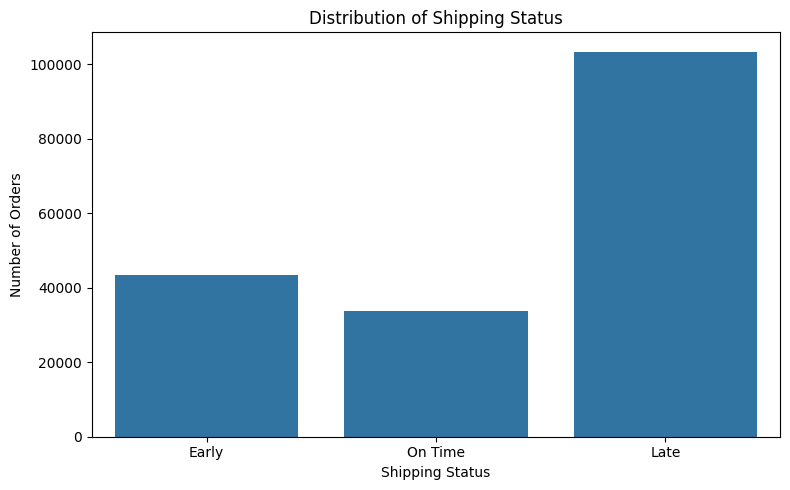

In [18]:
#Distribution of Shipping Duration
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Shipping Status',
    order=['Early', 'On Time', 'Late']
)

plt.title('Distribution of Shipping Status')
plt.xlabel('Shipping Status')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.savefig(
    'shipping_status.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## 17. Visualize Shipping Duration with a histogram
A histogram shows how frequently different shipping durations occur. It helps identify common durations and the overall distribution of shipping time.

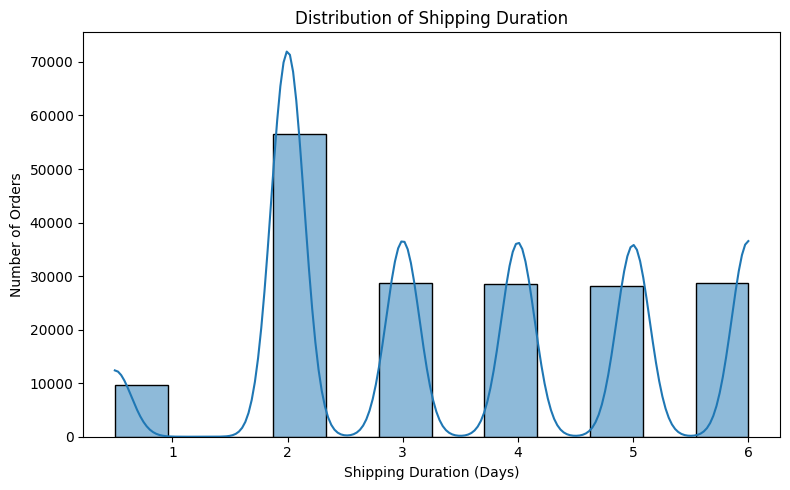

In [19]:
# Histogram of Shipping Duration

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='Shipping Duration',
    bins=12,
    kde=True
)

plt.title('Distribution of Shipping Duration')
plt.xlabel('Shipping Duration (Days)')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.savefig(
    'Histogram_shipping_Duration.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## 18. Examine Shipping Duration with a box plot
A box plot summarizes the median, quartiles and spread of Shipping Duration. It can also flag potential outliers.

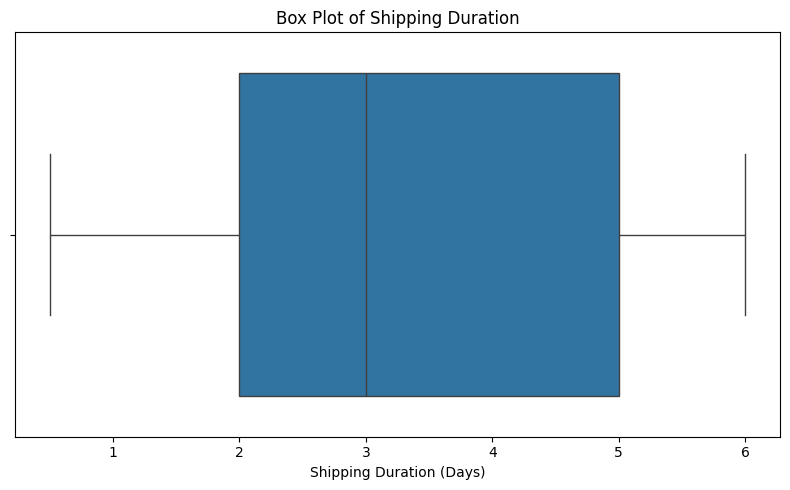

In [20]:
# Box Plot of Shipping Duration

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Shipping Duration'
)

plt.title('Box Plot of Shipping Duration')
plt.xlabel('Shipping Duration (Days)')

plt.tight_layout()
plt.savefig(
    'BoxPlot_shipping_Duration.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## 19. Explore Sales versus Shipping Duration
A scatter plot is used to inspect whether order sales amounts show a visible relationship with shipping duration. A lack of a visible trend would be consistent with a correlation close to zero.

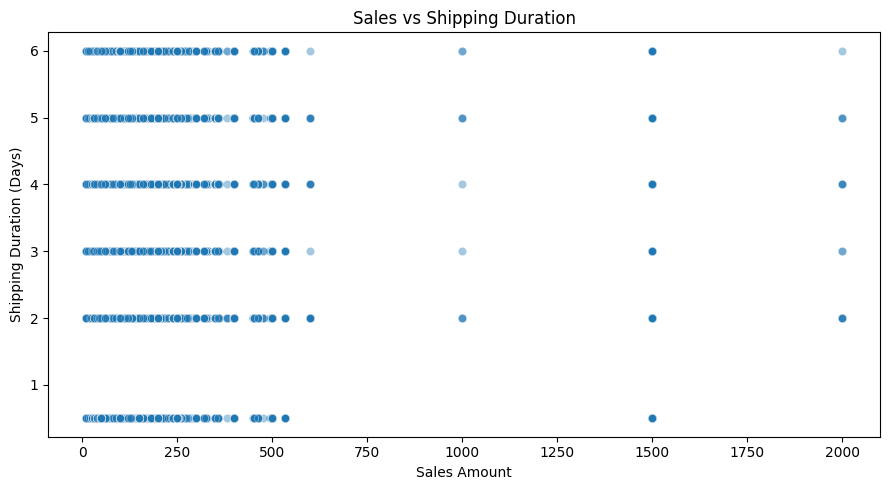

In [21]:
# Scatter Plot: Sales vs Shipping Duration
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x='Sales',
    y='Shipping Duration',
    alpha=0.4
)

plt.title('Sales vs Shipping Duration')
plt.xlabel('Sales Amount')
plt.ylabel('Shipping Duration (Days)')

plt.tight_layout()
plt.savefig(
    'Sales_Vs_Shipping_Duration.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [22]:
df_clean


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Shipping Duration,Duration Validation Difference,Scheduled Difference,Shipping Status
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-02-03 22:56:00,Standard Class,3.0,0.0,-1,Early
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-18 12:27:00,Standard Class,5.0,0.0,1,Late
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-17 12:06:00,Standard Class,4.0,0.0,0,On Time
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-16 11:45:00,Standard Class,3.0,0.0,-1,Early
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,http://images.acmesports.sports/Smart+watch,Smart watch,327.750000,0,2018-01-15 11:24:00,Standard Class,2.0,0.0,-2,Early
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,40.000000,399.980011,Shipping on time,0,45,Fishing,Brooklyn,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-20 03:40:00,Standard Class,4.0,0.0,0,On Time
180515,DEBIT,3,2,-613.770019,395.980011,Late delivery,1,45,Fishing,Bakersfield,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-19 01:34:00,Second Class,3.0,0.0,1,Late
180516,TRANSFER,5,4,141.110001,391.980011,Late delivery,1,45,Fishing,Bristol,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-20 21:00:00,Standard Class,5.0,0.0,1,Late
180517,PAYMENT,3,4,186.229996,387.980011,Advance shipping,0,45,Fishing,Caguas,...,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,2016-01-18 20:18:00,Standard Class,3.0,0.0,-1,Early


## 20. Verify the cleaned dataset
The final checks report the dataset shape, remaining missing values, duplicate rows and data types. These checks provide a concise quality-control summary after cleaning.

In [23]:

print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes.value_counts())


Final dataset shape: (180519, 55)

Missing values:
0

Duplicate rows:
0

Data types:
object            23
int64             15
float64           14
datetime64[ns]     2
string[python]     1
Name: count, dtype: int64


## Summary of Work Completed So Far

1. **Data Collection & Initial Inspection**
   - Mounted Google Drive and successfully loaded the **DataCo Smart Supply Chain Dataset** containing **180,519 rows** and **53 columns**.
   - Inspected missing value percentages, duplicate rows, and column data types.

2. **Data Cleaning & Handling Missing Values**
   - Dropped unnecessary/highly sparse columns: `Product Description` (100% missing) and `Order Zipcode` (86.2% missing).
   - Handled remaining missing values: filled missing `Customer Lname` with `'Unknown'` and resolved `Customer Zipcode` missing entries.
   - Converted standard numeric ZIP codes to string representation for consistency.

3. **Data Transformation & Feature Engineering**
   - Converted date features (`order date (DateOrders)` and `shipping date (DateOrders)`) into proper datetime formats.
   - Engineered `Shipping Duration` (actual days taken for shipping based on datetime difference).
   - Created validation metrics to cross-verify our calculated duration with the dataset's native `Days for shipping (real)` (showing a **94.61% exact match** rate and **97.42% approximate match** rate within decimal/integer rounding offsets).

4. **Delivery Performance Classification**
   - Calculated the gap between scheduled and actual delivery days (`Scheduled Difference`).
   - Segmented deliveries into **Early** (~24.02%), **On Time** (~18.70%), and **Late** (~57.28%) categories.

5. **Exploratory Visualizations**
   - Plotted delivery performance distribution charts (Bar charts, Histograms, Box Plots, and Sales vs. Shipping Duration scatter plots) and saved them locally as `shipping_status.png`.

# Week 2 – Exploratory Data Analysis (EDA)

Week 2 uses the cleaned dataset (`df_clean`) produced in Week 1. The objective is to summarize the data, examine relationships between numerical variables and communicate patterns through visualizations.

# TASK 2

## 21. Descriptive statistical analysis
Descriptive statistics summarize numerical columns using count, mean, standard deviation, minimum, quartiles and maximum. These measures provide an initial understanding of the scale and spread of the data.

In [24]:
# Descriptive statistical analysis
df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),180519.0,3.497654,0.0,2.0,3.0,5.0,6.0,1.623722
Days for shipment (scheduled),180519.0,2.931847,0.0,2.0,4.0,4.0,4.0,1.374449
Benefit per order,180519.0,21.974989,-4274.97998,7.0,31.52,64.800003,911.799988,104.433526
Sales per customer,180519.0,183.107609,7.49,104.379997,163.990005,247.399994,1939.98999,120.04367
Late_delivery_risk,180519.0,0.548291,0.0,0.0,1.0,1.0,1.0,0.497664
Category Id,180519.0,31.851451,2.0,18.0,29.0,45.0,76.0,15.640064
Customer Id,180519.0,6691.379495,1.0,3258.5,6457.0,9779.0,20757.0,4162.918106
Department Id,180519.0,5.44346,2.0,4.0,5.0,7.0,12.0,1.629246
Latitude,180519.0,29.719955,-33.937553,18.265432,33.144863,39.279617,48.781933,9.813646
Longitude,180519.0,-84.915675,-158.025986,-98.446312,-76.847908,-66.370583,115.263077,21.433241


## 22. Correlation analysis
Correlation measures the strength and direction of a linear relationship between numerical variables. Values closer to +1 indicate positive association, values closer to -1 indicate negative association, and values near 0 indicate little linear association.

**Caution:** Correlation does not establish causation. Identifier fields and constant-valued columns should not be interpreted as meaningful continuous measures.

In [25]:
# Calculate correlation between numerical variables
correlation = df_clean.corr(numeric_only=True)

# Display correlation with shipping duration
correlation['Shipping Duration'].sort_values(
    ascending=False
)

,Shipping Duration
Shipping Duration,1.000000
Days for shipping (real),0.997441
Scheduled Difference,0.610252
Days for shipment (scheduled),0.516353
Late_delivery_risk,0.386861
Duration Validation Difference,0.018708
Longitude,0.004863
Order Customer Id,0.003532
Customer Id,0.003532
Order Item Discount,0.002424


## 23. Correlation heatmap
The heatmap displays pairwise correlations among selected logistics and order variables. It is useful for comparing several relationships in one view.

**Selection rationale:** The selected columns focus on shipping duration, actual and scheduled shipping time, delivery risk, sales, quantity and discount rather than customer or order identifiers.

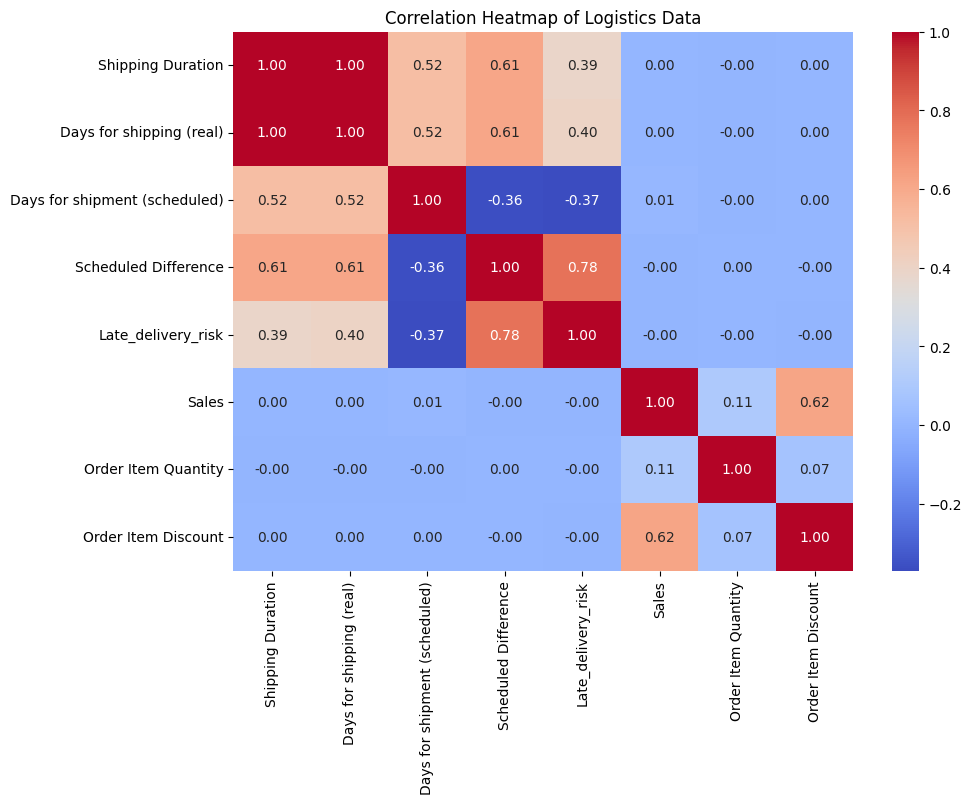

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select relevant numerical columns
selected_cols = [
    'Shipping Duration',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Scheduled Difference',
    'Late_delivery_risk',
    'Sales',
    'Order Item Quantity',
    'Order Item Discount'
]

# Calculate correlation
corr = df_clean[selected_cols].corr()

# Create heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Logistics Data')
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

#Correlation heatmap:
Shipping Duration has a strong positive correlation with actual shipping days (0.997), while Sales has almost no linear correlation with Shipping Duration (0.002).



## 24. Histogram of Shipping Duration
This histogram revisits the shipping-duration distribution as part of the Week 2 EDA task. It shows the frequency of orders at different shipping durations.

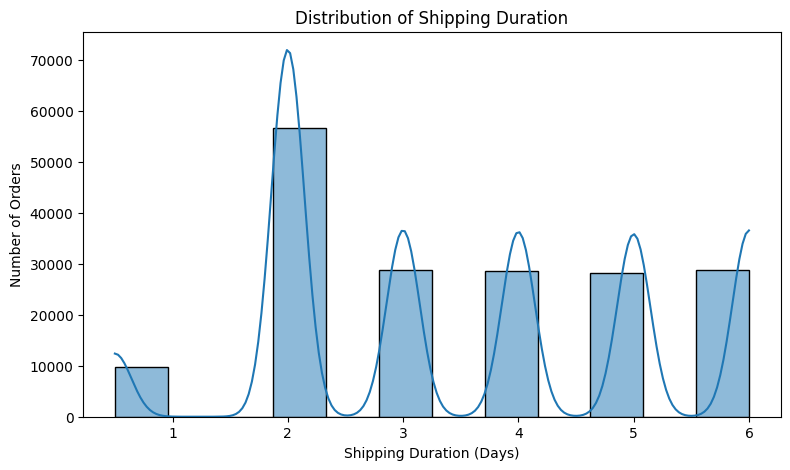

In [27]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x='Shipping Duration',
    bins=12,
    kde=True
)

plt.title('Distribution of Shipping Duration')
plt.xlabel('Shipping Duration (Days)')
plt.ylabel('Number of Orders')

plt.savefig('shipping_duration_histogram.png',
            dpi=300, bbox_inches='tight')

plt.show()


# Histogram:
 Most orders have a shipping duration of around 2 days, while the remaining orders are distributed across longer durations.

## 25. Box plot of Shipping Duration
The box plot complements the histogram by emphasizing the median, quartiles, spread and potential outliers.

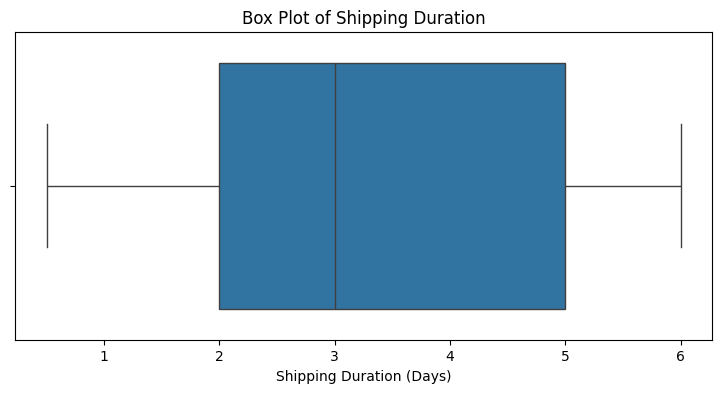

In [28]:
plt.figure(figsize=(9, 4))

sns.boxplot(x=df_clean['Shipping Duration'])

plt.title('Box Plot of Shipping Duration')
plt.xlabel('Shipping Duration (Days)')

plt.savefig('shipping_duration_boxplot.png',
            dpi=300, bbox_inches='tight')

plt.show()

# Box plot:
The median duration is 3 days, and the middle 50% of orders fall between 2 and 5 days. No prominent outliers are visible.

## 26. Shipping Duration versus Scheduled Difference
This scatter plot examines the relationship between the time taken to ship an order and the difference between actual and scheduled shipping days.

**Interpretation caution:** The two variables are mathematically related through the delivery-time calculation, so the association should be interpreted in that context.

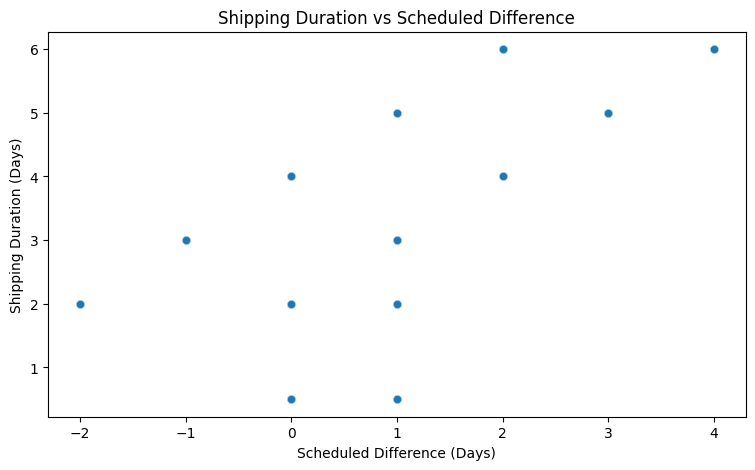

In [29]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x='Scheduled Difference',
    y='Shipping Duration',
    alpha=0.3
)

plt.title('Shipping Duration vs Scheduled Difference')
plt.xlabel('Scheduled Difference (Days)')
plt.ylabel('Shipping Duration (Days)')

plt.savefig('shipping_duration_scatter.png',
            dpi=300, bbox_inches='tight')

plt.show()

# Shipping Duration vs Scheduled Difference:
The plot shows a positive association: longer actual shipping durations generally accompany larger differences from scheduled shipping time.

## 27. Sales versus Shipping Duration
This scatter plot checks whether sales amount is linearly associated with shipping duration. It complements the correlation analysis with a visual inspection of the observations.

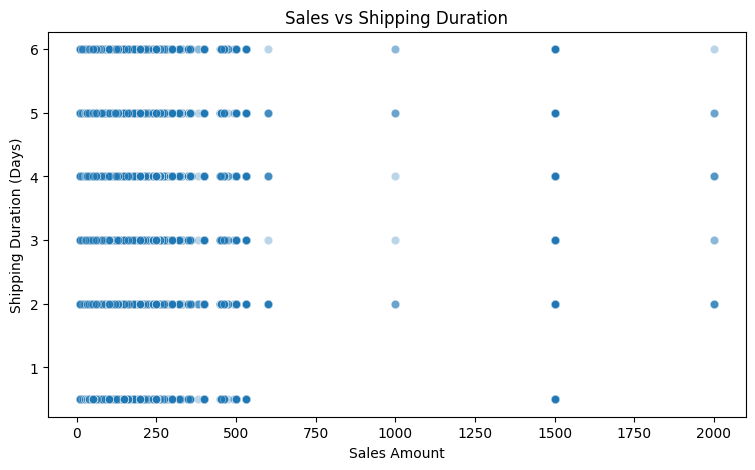

In [30]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x='Sales',
    y='Shipping Duration',
    alpha=0.3
)

plt.title('Sales vs Shipping Duration')
plt.xlabel('Sales Amount')
plt.ylabel('Shipping Duration (Days)')

plt.savefig('sales_vs_shipping_duration.png',
            dpi=300, bbox_inches='tight')

plt.show()

# Sales vs Shipping Duration:
There is no clear relationship between sales amount and shipping duration, consistent with the near-zero correlation.

# 28. Project Conclusion and Final Remarks

## Week 1 – Data preparation and delivery performance
- The original dataset contained **180,519 records and 53 columns**.
- `Product Description` and `Order Zipcode` were removed because they were highly incomplete.
- Remaining missing values in the customer name and ZIP code fields were handled using an `Unknown` label.
- Date fields were converted to datetime format and a new `Shipping Duration` feature was created.
- The calculated duration was compared with the existing actual shipping-days field. The recorded exact-match rate was **94.61%**, while the rounded-match rate was **97.42%**.
- Delivery status was classified by comparing actual shipping days with scheduled shipping days. The recorded distribution was **57.28% Late**, **24.02% Early** and **18.70% On Time**.

## Week 2 – Exploratory data analysis
- The mean Shipping Duration was approximately **3.50 days**, and the median was **3 days**.
- The middle 50% of shipping durations fell between **2 and 5 days**.
- Shipping Duration had a correlation of approximately **0.997** with `Days for shipping (real)`. This is expected because both variables represent closely related measures of actual shipping time.
- The correlation between Sales and Shipping Duration was approximately **0.002**, indicating almost no linear association in this dataset.
- The visualizations provide complementary views of category counts, distributions, spread and relationships between variables.

## Overall conclusion
The project demonstrates a workflow for preparing logistics data and exploring delivery performance. The cleaning and feature-engineering steps produce a dataset suitable for further analysis, while the Week 2 statistics and visualizations highlight delivery-time patterns and relationships among selected variables.

**Limitations:** Correlation describes association, not causation. The analysis is based on the available dataset and does not establish why a delivery was late. Any business recommendations should be supported by additional investigation of routes, carriers, locations, order timing and operational factors.


